In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
from scipy.io import loadmat

# Hide deprecation warnings!
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) 
import socket
hostname = socket.gethostname()

%matplotlib inline

In [2]:
# Set up paths
p = {}
if hostname == 'syndrome' or hostname == 'zod.psych.nyu.edu' or hostname == 'zod':
    p['datc'] =  '/d/DATD/datd/TMS_V3AB'
else:
    p['datc'] =  '/Users/mrugankdake/Documents/Clayspace/EEG_TMS/datd/TMS_V3AB'
p['data'] = p['datc'] + '/data'
p['analysis'] = p['datc'] + '/analysis'
p['meta'] = p['datc'] + '/analysis/meta_analysis'

if not os.path.exists(p['meta']):
    os.makedirs(p['meta'])

summary_df = pd.read_csv(os.path.join(p['analysis'] + '/V3AB_TMS_meta - Summary.csv'))
All_metadata = {row['Subject ID']: row for _, row in summary_df.iterrows()}

sub_dirs = [d for d in os.listdir(os.path.join(p['analysis'])) if d.startswith("sub")]
# Added temporarily while data collection is in progress
sub_dirs = ['sub02'] 
subjIDs = sorted([int(ss[-2:]) for ss in sub_dirs])

session_dfs = []
# Create a master dataframe
for ss in subjIDs:
    # Extract meta-data for this subject
    metadata = All_metadata[ss]
    subdir_name = f'sub{ss:02}'
    subject_row = summary_df[summary_df['Subject ID'] == ss].iloc[0]

    subjdir = os.path.join(p['analysis'], subdir_name) # Path of current subject directory
    phosphene_data_path = os.path.join(p['data'], 'phosphene_data',  subdir_name)

    # Load timestructure for this subject
    timeStructFname = os.path.join(subjdir, 'timeStruct.mat')
    timeStruct = loadmat(timeStructFname)['timeStruct']

    # Get list of all days this subject was run
    day_dirs = sorted(d for d in os.listdir(subjdir) if d.startswith("day"))
    days = []
    for dd in day_dirs:
        th_day = int(dd[-2:])
        print(f'Running subj = {ss}, day = {dd[-2:]}')
        daydir = os.path.join(subjdir, dd)

        sessfName = os.path.join(daydir, f'ii_sess_{subdir_name}_{dd}.mat')
        ii_sess = loadmat(sessfName)['ii_sess']
        tcount = len(ii_sess['t_num'][0, 0].T[0])

        # Extract times for this day
        idur = timeStruct['initDuration'][0, 0][th_day-1, :, :]
        sdur = timeStruct['sampleDuration'][0, 0][th_day-1, :, :]
        d1dur = timeStruct['delay1Duration'][0, 0][th_day-1, :, :]
        d2dur = timeStruct['delay2Duration'][0, 0][th_day-1, :, :]
        rdur = timeStruct['respDuration'][0, 0][th_day-1, :, :]
        fdur = timeStruct['feedbackDuration'][0, 0][th_day-1, :, :]
        itidur = timeStruct['itiDuration'][0, 0][th_day-1, :, :]
        trdur = timeStruct['trialDuration'][0, 0][th_day-1, :, :]

        sess_data = {
            'subjID': [ss] * tcount,
            'day': [th_day] * tcount,
            # Add the meta-data
            'gender': [metadata['Sex']] * tcount,
            'race': [metadata['Race']] * tcount,
            'handedness': [metadata['Handedness']] * tcount,
            'hemistimulated': [metadata['Hemisphere stimulated']] * tcount,
            'age': [metadata['Age']] * tcount,
            'weight': [metadata['Weight (kg)']] * tcount,
            'PT': [metadata['PT']] * tcount,
            'StimIntensity': [metadata['Stim Intensity']] * tcount,
            'Design': [metadata['Design Chosen']] * tcount,
            'NoTMSBlocks': [metadata['NoTMS Blocks']] * tcount,
            'TMSBlocks': [metadata['TMS Blocks']] * tcount,
            # Trial data
            'rnum': ii_sess['r_num'][0, 0].T[0],
            'tnum': ii_sess['t_num'][0, 0].T[0],
            'istms': ii_sess['istms'][0, 0].T[0], # 1 if TMS is on
            'instimVF': ii_sess['instimVF'][0, 0].T[0], # 1 if saccade is in VF
            # Trial flags
            'bad_drift_correct': ii_sess['bad_drift_correct'][0, 0].T[0], # Flag 11
            'bad_calibration': ii_sess['bad_calibration'][0, 0].T[0], # Flag 12
            'breakfix': ii_sess['break_fix'][0, 0].T[0], # Flag 13
            'no_prim_sacc': ii_sess['no_prim_sacc'][0, 0].T[0], # Flag 20
            'small_sacc': ii_sess['small_sacc'][0, 0].T[0], # Flag 21
            'large_error': ii_sess['large_error'][0, 0].T[0], # Flag 22
            'rejtrials': ii_sess['rejtrials'][0, 0].T[0], # Flags 20 and 22, can be updated here directly
            # Target and eye end-points
            'TarX': ii_sess['targ'][0, 0][:, 0].T,
            'TarY': ii_sess['targ'][0, 0][:, 1].T,
            'isaccX': ii_sess['i_sacc_raw'][0, 0][:, 0].T,
            'isaccY': ii_sess['i_sacc_raw'][0, 0][:, 1].T,
            'fsaccX': ii_sess['f_sacc_raw'][0, 0][:, 0].T,
            'fsaccY': ii_sess['f_sacc_raw'][0, 0][:, 1].T,
            # errors added
            'isacc_err': ii_sess['i_sacc_err'][0, 0].T[0], # raw euclidean distance error wrt target for isacc
            'fsacc_err': ii_sess['f_sacc_err'][0, 0].T[0], # raw euclidean distance error wrt target for fsacc
            'nsacc': ii_sess['n_sacc'][0, 0].T[0],
            # Reaction times added
            'isacc_rt': ii_sess['i_sacc_rt'][0, 0].T[0], # RT for isacc wrt response epoch start
            'fsacc_rt': ii_sess['f_sacc_rt'][0, 0].T[0], # RT for fsacc wrt response epoch start
            # Velocities
            'isacc_peakvel': ii_sess['i_sacc_peakvel'][0, 0].T[0],
            'fsacc_peakvel': ii_sess['f_sacc_peakvel'][0, 0].T[0],
            # Add timereports for each epoch
            'initdur': idur[~np.isnan(idur)].flatten(),
            'sampledur': sdur[~np.isnan(sdur)].flatten(),
            'delay1dur': d1dur[~np.isnan(d1dur)].flatten(),
            'delay2dur': d2dur[~np.isnan(d2dur)].flatten(),
            'respdur': rdur[~np.isnan(rdur)].flatten(),
            'feedbackdur': fdur[~np.isnan(fdur)].flatten(),
            'itidur': itidur[~np.isnan(itidur)].flatten(),
            'trialdur': trdur[~np.isnan(trdur)].flatten(),
        }
        session_dfs.append(pd.DataFrame(sess_data))
        this_sess_df = pd.DataFrame(sess_data)


Running subj = 2, day = 01
Running subj = 2, day = 02


In [3]:
# Compile saccade traces across all trials
screen_dva = 20
x_space = np.linspace(-screen_dva, screen_dva, 1000)
y_space = np.linspace(-screen_dva, screen_dva, 1000)
conds = ['notms', 'tms']
instimVF_traces = np.zeros((len(subjIDs), len(conds), len(x_space)-1, len(y_space)-1))
outstimVF_traces = np.zeros((len(subjIDs), len(conds), len(x_space)-1, len(y_space)-1))

for s_idx in range(len(subjIDs)):
    ss = subjIDs[s_idx]
    subjdir = os.path.join(p['analysis'], f'sub{ss:02}')
    day_dirs = sorted(d for d in os.listdir(subjdir) if d.startswith("day"))

    for d_idx in range(len(day_dirs)):
        dd = day_dirs[d_idx]
        ii_sess = loadmat(os.path.join(subjdir, dd, f'ii_sess_sub{ss:02}_{dd}.mat'))['ii_sess']
        tcount = len(ii_sess['t_num'][0, 0].T[0])
        instimVF = ii_sess['instimVF'][0, 0].T[0]
        for trl in range(tcount):
            # Check if saccade trace exists for this trial
            if ~np.isnan(ii_sess['i_sacc_err'][0, 0][trl, 0]):
                x_trace = np.concatenate((ii_sess['i_sacc_trace'][0, 0][trl, 0][:, 0], ii_sess['f_sacc_trace'][0, 0][trl, 0][:, 0]))
                y_trace = np.concatenate((ii_sess['i_sacc_trace'][0, 0][trl, 0][:, 1], ii_sess['f_sacc_trace'][0, 0][trl, 0][:, 1]))
                
                if instimVF[trl] == 1:
                    instimVF_traces[s_idx, d_idx, :, :] += np.flip(np.histogram2d(x_trace, y_trace, bins=[x_space, y_space])[0], axis=[1])
                else:
                    outstimVF_traces[s_idx, d_idx, :, :] += np.flip(np.histogram2d(x_trace, y_trace, bins=[x_space, y_space])[0], axis=[1])

        # Normalize traces
        instimVF_traces[s_idx, d_idx, :, :] /= np.max(instimVF_traces[s_idx, d_idx, :, :])
        outstimVF_traces[s_idx, d_idx, :, :] /= np.max(outstimVF_traces[s_idx, d_idx, :, :])

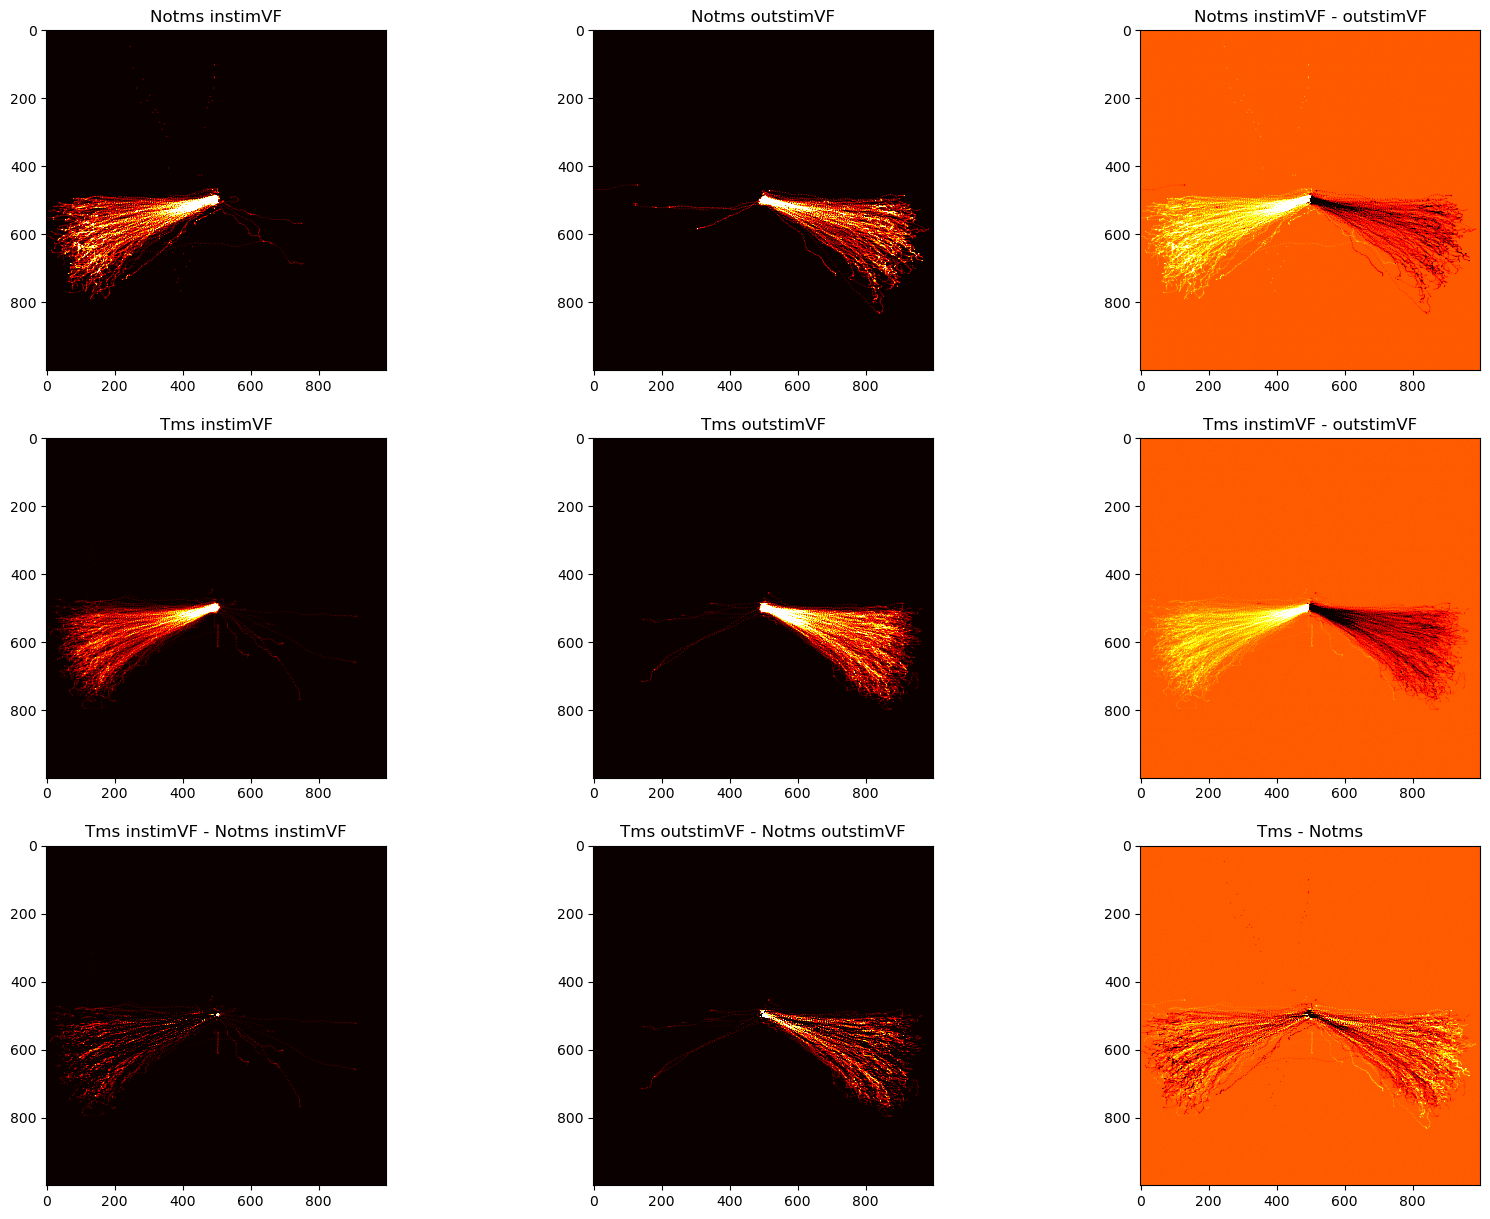

In [4]:
# Plot histrogram for each subject for notms and tms
mval = 0.05
cmap_name = 'hot'
for s_idx in range(len(subjIDs)):
    fig, ax = plt.subplots(3, 3, figsize=(20, 15))
    
    ax[0, 0].imshow(instimVF_traces[s_idx, 0, :, :].T, cmap=cmap_name, vmin=0, vmax=mval)
    ax[0, 0].set_title('Notms instimVF')
    
    ax[0, 1].imshow(outstimVF_traces[s_idx, 0, :, :].T, cmap=cmap_name, vmin=0, vmax=mval)
    ax[0, 1].set_title('Notms outstimVF')

    ax[0, 2].imshow(instimVF_traces[s_idx, 0, :, :].T - outstimVF_traces[s_idx, 0, :, :].T, cmap=cmap_name, vmin=-mval, vmax=mval)
    ax[0, 2].set_title('Notms instimVF - outstimVF')

    ax[1, 0].imshow(instimVF_traces[s_idx, 1, :, :].T, cmap=cmap_name, vmin=0, vmax=mval)
    ax[1, 0].set_title('Tms instimVF')

    ax[1, 1].imshow(outstimVF_traces[s_idx, 1, :, :].T, cmap=cmap_name, vmin=0, vmax=mval)
    ax[1, 1].set_title('Tms outstimVF')

    ax[1, 2].imshow(instimVF_traces[s_idx, 1, :, :].T - outstimVF_traces[s_idx, 1, :, :].T, cmap=cmap_name, vmin=-mval, vmax=mval)
    ax[1, 2].set_title('Tms instimVF - outstimVF')

    ax[2, 0].imshow(instimVF_traces[s_idx, 1, :, :].T - instimVF_traces[s_idx, 0, :, :].T, cmap=cmap_name, vmin=0, vmax=mval)
    ax[2, 0].set_title('Tms instimVF - Notms instimVF')

    ax[2, 1].imshow(outstimVF_traces[s_idx, 1, :, :].T - outstimVF_traces[s_idx, 0, :, :].T, cmap=cmap_name, vmin=0, vmax=mval)
    ax[2, 1].set_title('Tms outstimVF - Notms outstimVF')

    ax[2, 2].imshow((instimVF_traces[s_idx, 1, :, :] - outstimVF_traces[s_idx, 1, :, :]).T - (instimVF_traces[s_idx, 0, :, :] - outstimVF_traces[s_idx, 0, :, :]).T, cmap=cmap_name, vmin=-mval, vmax=mval)
    ax[2, 2].set_title('Tms - Notms')

    plt.show()

In [115]:
valid_flags = [1, 2, 3, 4, 5, 6, 7]
ntrls_per_block = 40
max_block = 25
max_trials = ntrls_per_block * max_block

# Explore fixation and gaze drifts
sub_dirs = [d for d in os.listdir(os.path.join(p['analysis'])) if d.startswith("sub")]
# Added temporarily while data collection is in progress
sub_dirs = ['sub11'] 
subjIDs = sorted([int(ss[-2:]) for ss in sub_dirs])

conds = ['notms', 'tms']

X_master = np.empty((len(subjIDs), len(conds), max_trials, len(valid_flags)-1, 10000))
Y_master = np.empty((len(subjIDs), len(conds), max_trials, len(valid_flags)-1, 10000))
Pupil_master = np.empty((len(subjIDs), len(conds), max_trials, len(valid_flags)-1, 10000))
stimVF_master = np.empty((len(subjIDs), len(conds), max_trials))

# Create a master dataframe
for s_idx in range(len(subjIDs)):
    ss = subjIDs[s_idx]
    # Extract meta-data for this subject
    metadata = All_metadata[ss]
    subdir_name = f'sub{ss:02}'
    subject_row = summary_df[summary_df['Subject ID'] == ss].iloc[0]

    subjdir = os.path.join(p['analysis'], subdir_name) # Path of current subject directory
    phosphene_data_path = os.path.join(p['data'], 'phosphene_data',  subdir_name)

    # Load timestructure for this subject
    timeStructFname = os.path.join(subjdir, 'timeStruct.mat')
    timeStruct = loadmat(timeStructFname)['timeStruct']

    # Get list of all days this subject was run
    day_dirs = sorted(d for d in os.listdir(subjdir) if d.startswith("day"))
    days = []
    for d_idx in range(len(day_dirs)):
        dd = day_dirs[d_idx]
        th_day = int(dd[-2:])
        print(f'Running subj = {ss}, day = {dd[-2:]}')
        daydir = os.path.join(subjdir, dd)

        sessfName = os.path.join(daydir, f'ii_sess_{subdir_name}_{dd}.mat')
        ii_sess = loadmat(sessfName)['ii_sess']
        instimVF = ii_sess['instimVF'][0, 0].T[0]
        stimVF_master[s_idx, d_idx, :len(instimVF)] = instimVF

        # Number of blocks for this day
        if dd == 'day01':
            blocks = int(All_metadata[ss]['NoTMS Blocks'])
        else:
            blocks = int(All_metadata[ss]['TMS Blocks'])
        
        for bb in range(blocks):
            blockdir = os.path.join(daydir, 'EyeData', f'block{bb+1:02}')
            dataFile = [f for f in os.listdir(blockdir) if f.endswith('.mat')][0]
            
            # Load eye data
            eye_data = loadmat(os.path.join(blockdir, dataFile))
            X_data = eye_data['ii_data']['X'][0, 0].T[0]
            Y_data = eye_data['ii_data']['Y'][0, 0].T[0]
            XDAT_data = eye_data['ii_data']['XDAT'][0, 0].T[0]
            Pupil_data = eye_data['ii_data']['Pupil'][0, 0].T[0]

            # Get samples for all epochs
            flag_changer = np.where(np.diff(XDAT_data) > 0)[0]
            
            samp_tracker = np.zeros((len(valid_flags), ntrls_per_block), dtype=int)
            counter_xdat = np.zeros((len(valid_flags),), dtype=int)
            for fl_idx in range(len(valid_flags)):
                flg_samps = np.where(XDAT_data == valid_flags[fl_idx])[0]
                for idx in range(len(flg_samps)-1):
                    if idx == 0:
                        samp_tracker[fl_idx, counter_xdat[fl_idx]] = flg_samps[idx]
                        counter_xdat[fl_idx] += 1
                    else:
                        if flg_samps[idx+1] - flg_samps[idx] > 1:
                            samp_tracker[fl_idx, counter_xdat[fl_idx]] = flg_samps[idx+1]
                            counter_xdat[fl_idx] += 1
                        
            # Extract gaze coords and pupil for each epoch
            for f_idx in range(len(valid_flags)-1):
                for trl in range(ntrls_per_block):
                    if ~np.isnan(samp_tracker[f_idx, trl]):
                        this_xdata = X_data[samp_tracker[f_idx, trl]:samp_tracker[f_idx+1, trl]]
                        this_ydata = Y_data[samp_tracker[f_idx, trl]:samp_tracker[f_idx+1, trl]]
                        this_pupil = Pupil_data[samp_tracker[f_idx, trl]:samp_tracker[f_idx+1, trl]]

                        X_master[s_idx, d_idx, int(bb*ntrls_per_block + trl), f_idx, :len(this_xdata)] = this_xdata
                        Y_master[s_idx, d_idx, int(bb*ntrls_per_block + trl), f_idx, :len(this_ydata)] = this_ydata
                        Pupil_master[s_idx, d_idx, int(bb*ntrls_per_block + trl), f_idx, :len(this_pupil)] = this_pupil

Running subj = 11, day = 01
Running subj = 11, day = 02


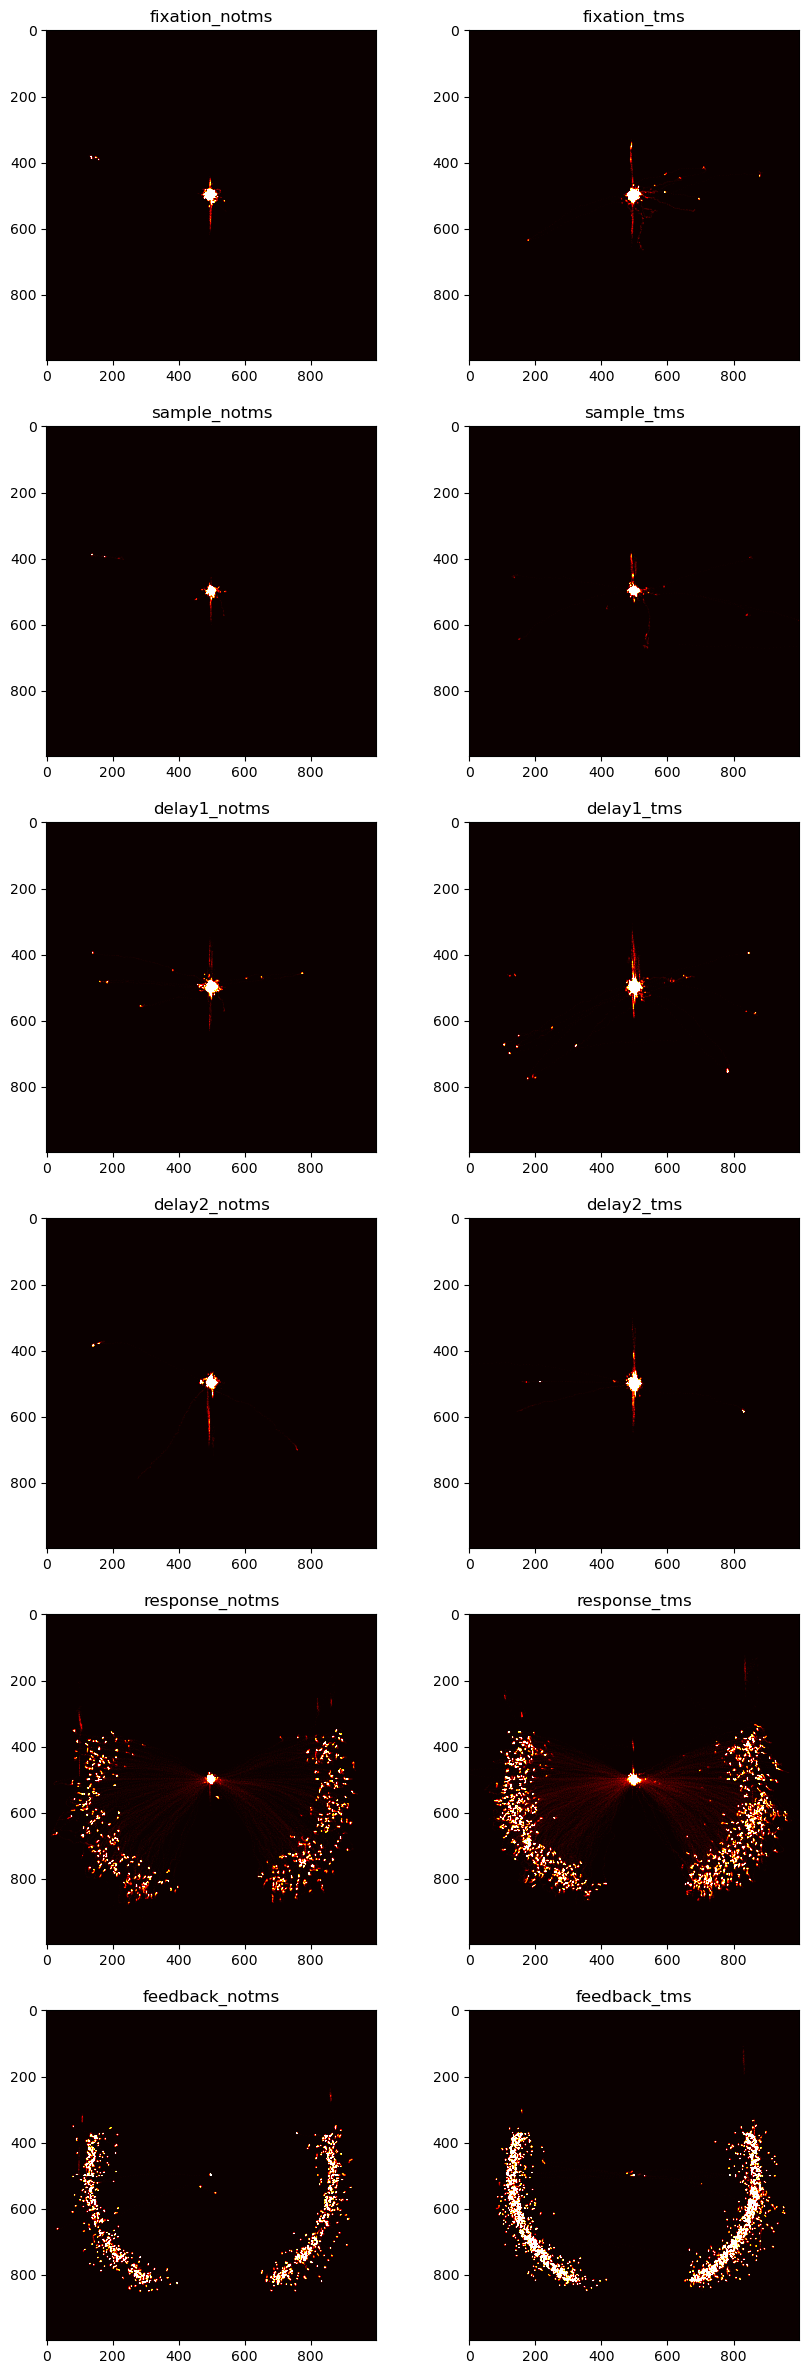

In [116]:
# Plot gaze for each epoch for instimVF and outstimVF for each subject and for each condition
screen_dva = 20
epoch_names = ['fixation', 'sample', 'delay1', 'delay2', 'response', 'feedback']
x_space = np.linspace(-screen_dva, screen_dva, 1000)
y_space = np.linspace(-screen_dva, screen_dva, 1000)
for s_idx in range(len(subjIDs)):
    f, axs = plt.subplots(len(valid_flags)-1, 2, figsize=(10, 30))
    axs_flat = axs.flatten()
    for f_idx in range(len(valid_flags)-1):
        for c_idx in range(2):
            gaze_coords = np.histogram2d(X_master[s_idx, c_idx, :, f_idx, :].flatten(), Y_master[s_idx, c_idx, :, f_idx, :].flatten(), bins=[x_space, y_space])[0]    
            gaze_coords = np.flip(gaze_coords, axis=[1])
            gaze_coords /= np.nanmax(gaze_coords)
            std_coords = np.var(gaze_coords.flatten())
            axs_flat[f_idx*2+c_idx].imshow(gaze_coords.T, cmap='hot', vmin=0, vmax=std_coords) 
            axs_flat[f_idx*2+c_idx].set_title(f'{epoch_names[f_idx]}_{conds[c_idx]}')
    plt.show()

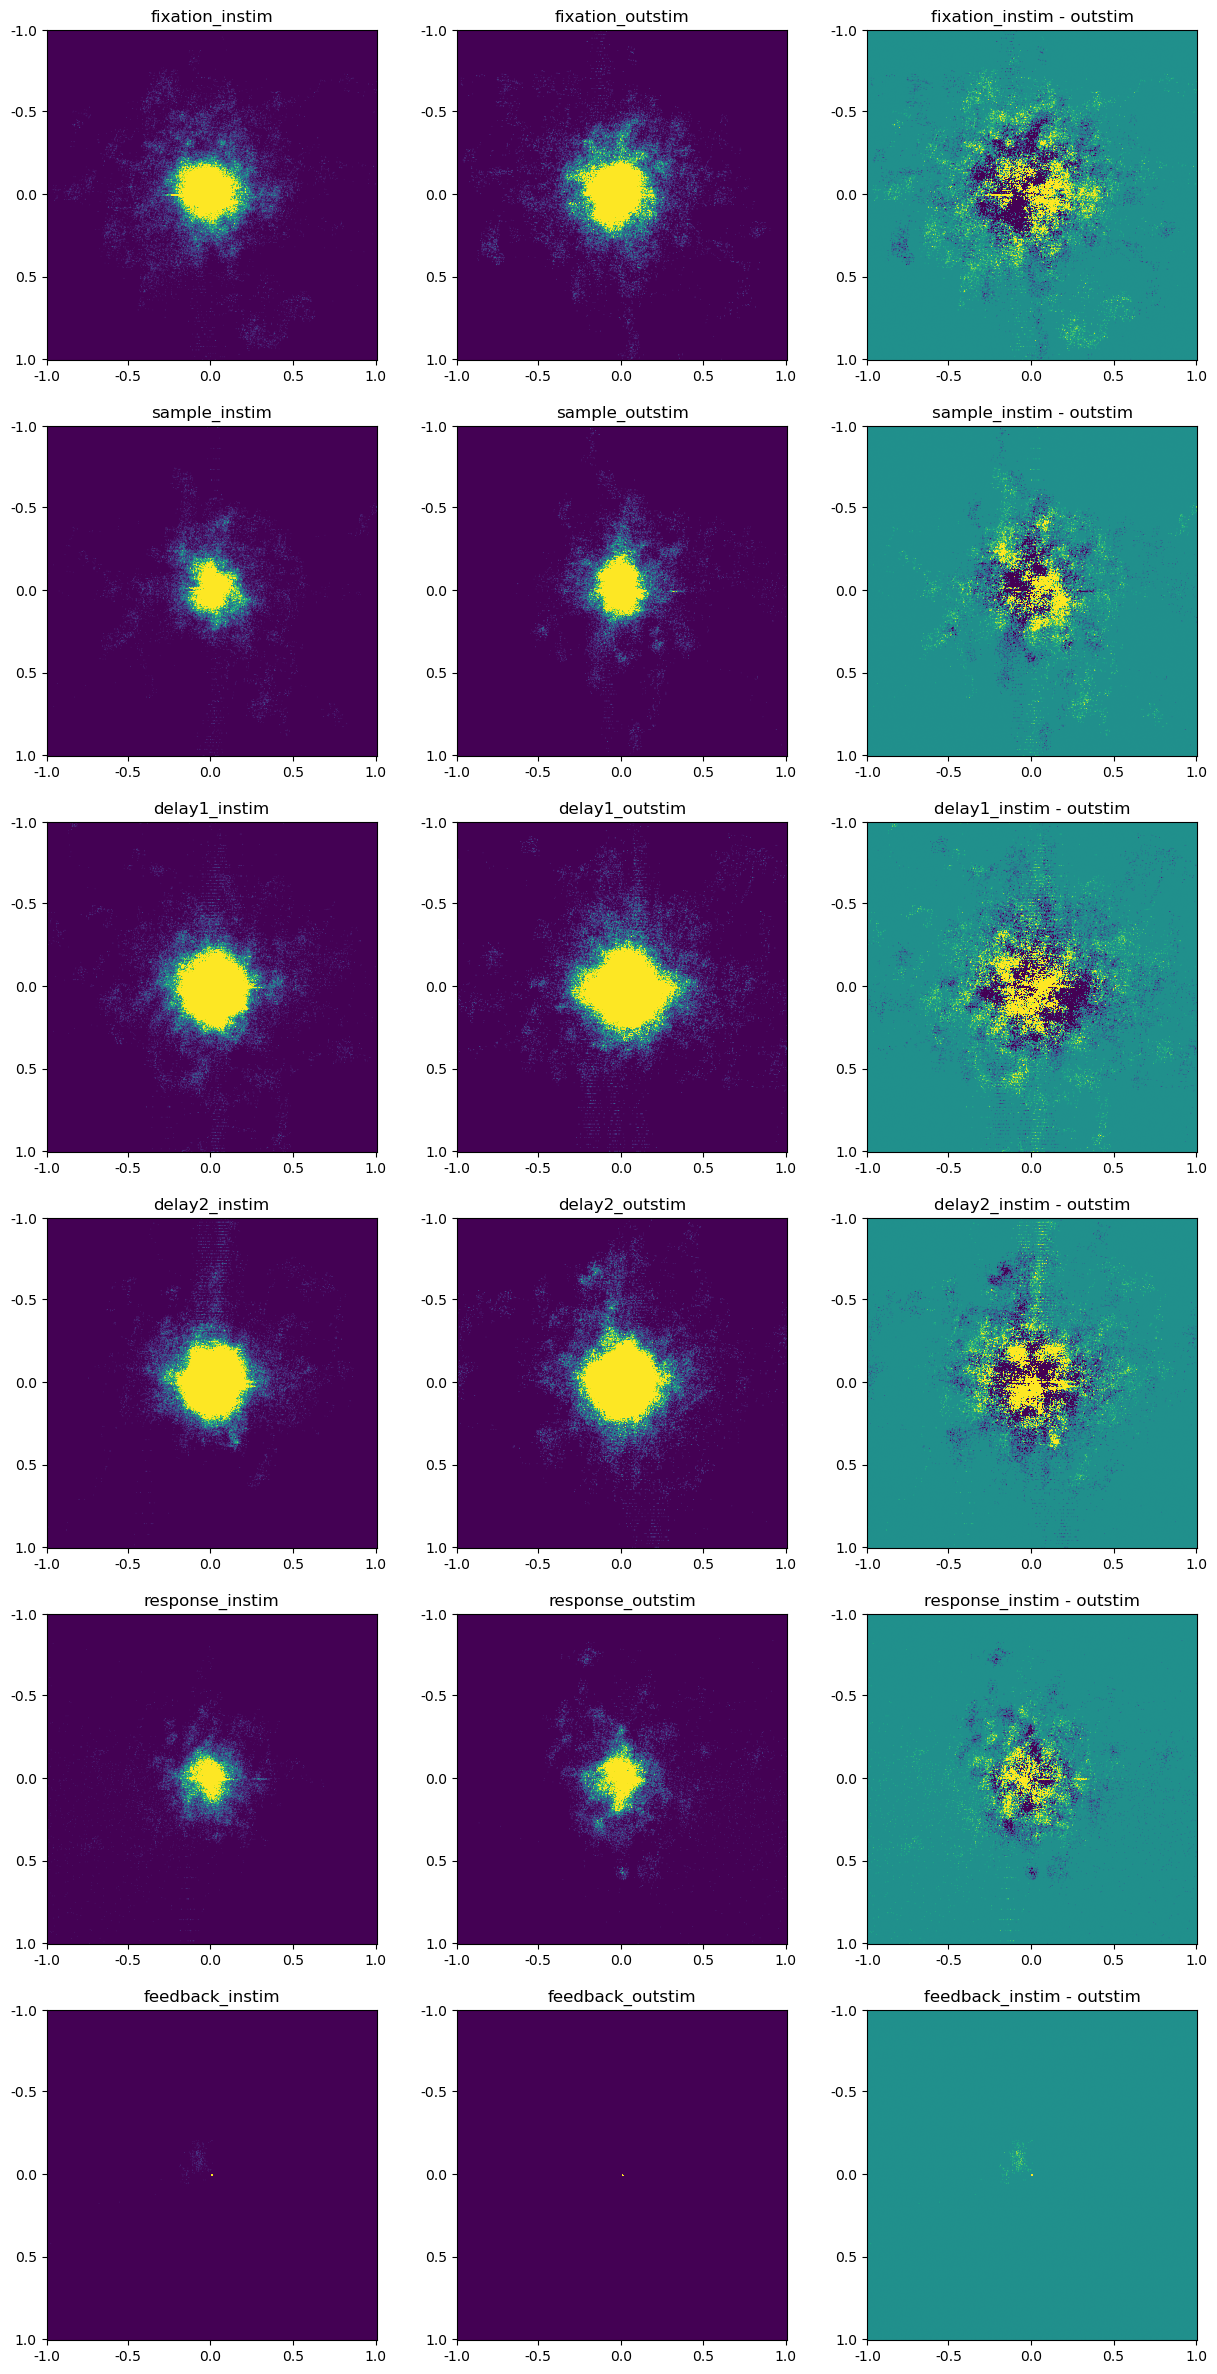

In [118]:
# Plot gaze for each epoch for instimVF and outstimVF for each subject and for each condition
screen_dva = 20
epoch_names = ['fixation', 'sample', 'delay1', 'delay2', 'response', 'feedback']
cmap_name = 'viridis'
fov = 1
cond_val = 0
x_space = np.linspace(-fov, fov, 1000)
y_space = np.linspace(-fov, fov, 1000)
if fov >= 1:
    x_tick_vals = np.round(np.arange(-fov, fov+0.5, 0.5), 1)
    y_tick_vals = np.round(np.arange(-fov, fov+0.5, 0.5), 1)
    x_tick_idx = [np.where(np.abs(x_space - val) < 1e-2)[0][0] for val in x_tick_vals]
    y_tick_idx = [np.where(np.abs(y_space - val) < 1e-2)[0][0] for val in y_tick_vals]

else:
    x_tick_vals = np.round(np.arange(-fov, fov+0.25, 0.25), 2)
    y_tick_vals = np.round(np.arange(-fov, fov+0.25, 0.25), 2)
    x_tick_idx = [np.where(np.abs(x_space - val) < 1e-3)[0][0] for val in x_tick_vals]
    y_tick_idx = [np.where(np.abs(y_space - val) < 1e-3)[0][0] for val in y_tick_vals]

for s_idx in range(len(subjIDs)):
    f, axs = plt.subplots(len(valid_flags)-1, 3, figsize=(15, 30))
    axs_flat = axs.flatten()
    for f_idx in range(len(valid_flags)-1):
        trl_idx_instim = np.where(stimVF_master[s_idx, 0, :] == 0)[0]
        trl_idx_outstim = np.where(stimVF_master[s_idx, 0, :] == 1)[0]

        gaze_coords_instim = np.histogram2d(X_master[s_idx, cond_val, trl_idx_instim, f_idx, :].flatten(), Y_master[s_idx, cond_val, trl_idx_instim, f_idx, :].flatten(), bins=[x_space, y_space])[0]
        gaze_coords_instim = np.flip(gaze_coords_instim, axis=[1])
        gaze_coords_instim_plot = gaze_coords_instim / np.nanmax(gaze_coords_instim)
        max_val_instim = np.var(gaze_coords_instim_plot.flatten())
        axs_flat[f_idx*3].imshow(gaze_coords_instim_plot.T, cmap=cmap_name, vmin=0, vmax=max_val_instim)
        axs_flat[f_idx*3].set_title(f'{epoch_names[f_idx]}_instim')
        axs_flat[f_idx*3].set_xticks(x_tick_idx)
        axs_flat[f_idx*3].set_yticks(y_tick_idx)
        axs_flat[f_idx*3].set_xticklabels(x_tick_vals)
        axs_flat[f_idx*3].set_yticklabels(y_tick_vals)

        gaze_coords_outstim = np.histogram2d(X_master[s_idx, cond_val, trl_idx_outstim, f_idx, :].flatten(), Y_master[s_idx, cond_val, trl_idx_outstim, f_idx, :].flatten(), bins=[x_space, y_space])[0]
        gaze_coords_outstim = np.flip(gaze_coords_outstim, axis=[1])
        gaze_coords_outstim_plot = gaze_coords_outstim / np.nanmax(gaze_coords_outstim)
        max_val_outstim = np.var(gaze_coords_outstim_plot.flatten())
        axs_flat[f_idx*3+1].imshow(gaze_coords_outstim_plot.T, cmap=cmap_name, vmin=0, vmax=max_val_outstim)
        axs_flat[f_idx*3+1].set_title(f'{epoch_names[f_idx]}_outstim')
        axs_flat[f_idx*3+1].set_xticks(x_tick_idx)
        axs_flat[f_idx*3+1].set_yticks(y_tick_idx)
        axs_flat[f_idx*3+1].set_xticklabels(x_tick_vals)
        axs_flat[f_idx*3+1].set_yticklabels(y_tick_vals)

        gaze_coords_diff = gaze_coords_instim - gaze_coords_outstim
        gaze_coords_diff_plot = gaze_coords_diff / np.nanmax(gaze_coords_diff)
        max_val_diff = np.var(gaze_coords_diff_plot.flatten())
        axs_flat[f_idx*3+2].imshow(gaze_coords_diff_plot.T, cmap=cmap_name, vmin=-max_val_diff, vmax=max_val_diff)
        axs_flat[f_idx*3+2].set_title(f'{epoch_names[f_idx]}_instim - outstim')
        axs_flat[f_idx*3+2].set_xticks(x_tick_idx)
        axs_flat[f_idx*3+2].set_yticks(y_tick_idx)
        axs_flat[f_idx*3+2].set_xticklabels(x_tick_vals)
        axs_flat[f_idx*3+2].set_yticklabels(y_tick_vals)
    plt.show()

In [150]:
df1 = pd.read_csv('/d/DATD/datd/TMS_V3AB/analysis/meta_analysis/master_df_calibrun.csv')
df2 = pd.read_csv('/d/DATD/datd/TMS_V3AB/analysis/meta_analysis/master_df.csv')
df2 = df2[df2['subjID'] != 11]

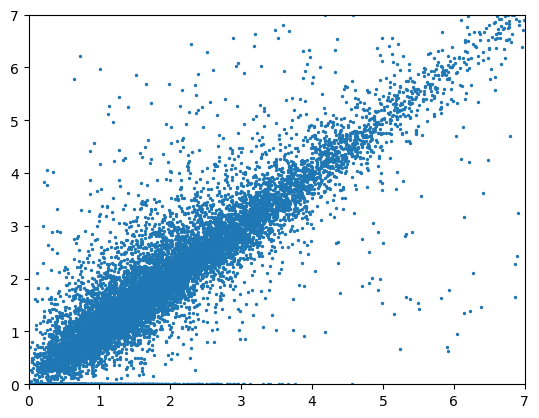

In [151]:
n_subplots = df1['subjID'].unique()
n_cols = 2
n_rows = len(n_subplots) // n_cols

plt.figure()
plt.scatter(df1['isacc_err'], df2['isacc_err'], s=2)
plt.xlim([0, 7])
plt.ylim([0, 7])
plt.show()